
# CA-3: Hotel Booking Cancellation Prediction

## Project Aim
Develop and evaluate machine learning models to predict whether a hotel booking will be cancelled using historical hotel booking data.

## Research Question
Can machine learning models predict hotel booking cancellations accurately and identify the factors most strongly associated with cancellation risk?

## Objectives
1. Understand and explore the hotel booking dataset.
2. Prepare the data for machine learning.
3. Develop and optimise multiple classification models.
4. Compare models using appropriate performance metrics.
5. Interpret model predictions using SHAP.
6. Provide evidence-based recommendations for hotel revenue and resource planning.

## Tools
Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn and SHAP, alongside the required model-specific libraries.


In [1]:

# Importing the core data analysis libraries
import pandas as pd
import numpy as np

# Importing the visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Importing utilities for file paths and display settings
from pathlib import Path
from IPython.display import display

# Configuring the notebook display
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


In [6]:

# Uploading the hotel booking CSV file
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [7]:
df = pd.read_csv("/content/drive/MyDrive/Raw Dataset/hotel_bookings.csv")
# Loading the dataset
print("Dataset loaded successfully.")


Dataset loaded successfully.


In [12]:

# Inspecting column names and data types
display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Missing Values": df.isna().sum().values,
        "Unique Values": df.nunique(dropna=False).values
    })
)

# Inspecting the dataset structure
#df.info()

,Column,Data Type,Missing Values,Unique Values
0,hotel,object,0,2
1,is_canceled,int64,0,2
2,lead_time,int64,0,479
3,arrival_date_year,int64,0,3
4,arrival_date_month,object,0,12
5,arrival_date_week_number,int64,0,53
6,arrival_date_day_of_month,int64,0,31
7,stays_in_weekend_nights,int64,0,17
8,stays_in_week_nights,int64,0,35
9,adults,int64,0,14


In [13]:
df.shape

(119390, 32)

# EDA

In [16]:
# Checking for duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

# Checking missing values and their percentages
missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_data = missing_data[missing_data["Missing Values"] > 0]
missing_data = missing_data.sort_values(
    by="Missing Percentage", ascending=False
)

display(missing_data.round(2))

Number of duplicate rows: 31994


,Missing Values,Missing Percentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [15]:
# Checking the number of cancelled and non-cancelled bookings
print("Booking cancellation counts:")
display(df["is_canceled"].value_counts())

# Checking the percentage of each target class
print("Booking cancellation percentages:")
display((df["is_canceled"].value_counts(normalize=True) * 100).round(2))


Booking cancellation counts:


,count
is_canceled,
0,75166
1,44224


Booking cancellation percentages:


,proportion
is_canceled,
0,62.96
1,37.04



### Duplicate Record Analysis
This section examines duplicate records and compares their cancellation rates with unique records.


In [19]:

# Identifying duplicated records in the dataset
duplicate_rows = df.duplicated()

print("Unique records:", (~duplicate_rows).sum())
print("Duplicate records:", duplicate_rows.sum())

# Comparing cancellation rates in duplicated and unique records
duplicate_analysis = df.groupby(duplicate_rows)["is_canceled"].agg(
    ["count", "mean"]
)

duplicate_analysis["Cancellation Percentage"] = (
    duplicate_analysis["mean"] * 100
)

display(duplicate_analysis.round(2))


Unique records: 87396
Duplicate records: 31994


,count,mean,Cancellation Percentage
False,87396,0.27,27.49
True,31994,0.63,63.13



### Booking Cancellation Distribution
This section visualises the number of cancelled and non-cancelled bookings.


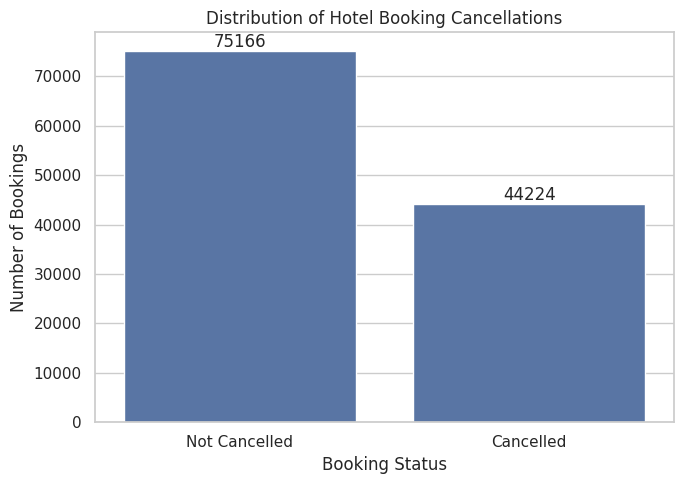

In [27]:
# Counting cancelled and non-cancelled bookings
cancellation_counts = df["is_canceled"].value_counts().sort_index()

# Visualising the cancellation distribution
plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=["Not Cancelled", "Cancelled"],
    y=cancellation_counts.values
)

# Displaying booking counts above each bar
ax.bar_label(
    ax.containers[0]
)

plt.title("Distribution of Hotel Booking Cancellations")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()



### Cancellation Rate by Hotel Type
This section compares booking cancellation rates between city hotels and resort hotels.


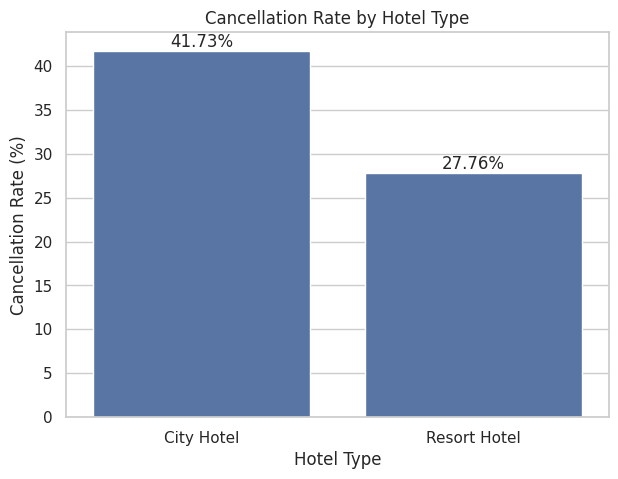

In [25]:

# Calculating cancellation rates by hotel type
hotel_cancellation = df.groupby("hotel")["is_canceled"].mean() * 100

# Visualising cancellation rates by hotel type
plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=hotel_cancellation.index,
    y=hotel_cancellation.values
)

# Displaying cancellation percentages above each bar
ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%"
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.show()


### Cancellation Rate by Market Segment
This section compares booking cancellation rates across different market segments.


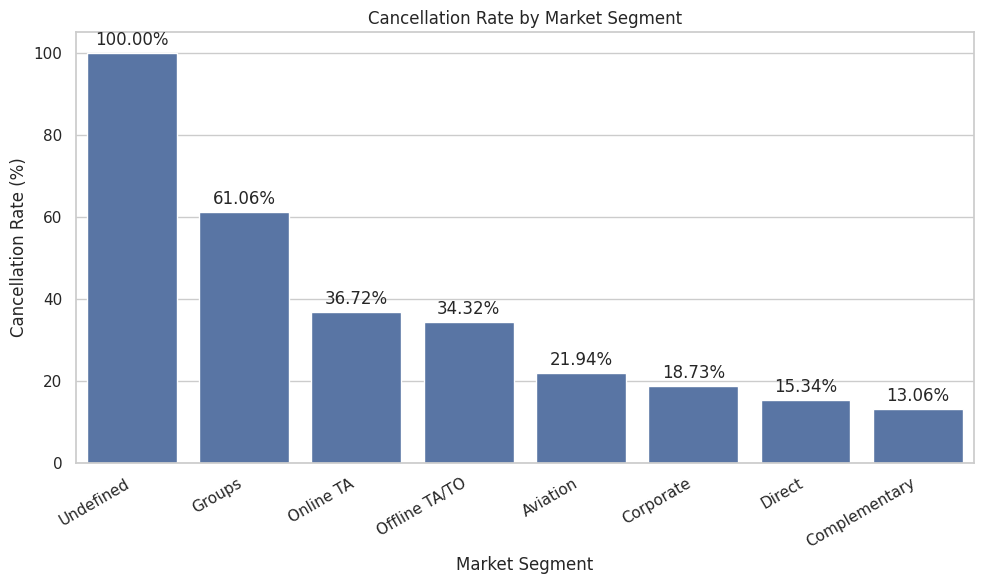

In [30]:
# Calculating cancellation rates across market segments
market_cancellation = (
    df.groupby("market_segment")["is_canceled"].mean() * 100
).sort_values(ascending=False)

# Visualising cancellation rates by market segment
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=market_cancellation.index,
    y=market_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()



### Cancellation Rate by Deposit Type
This section examines how deposit requirements relate to booking cancellations.


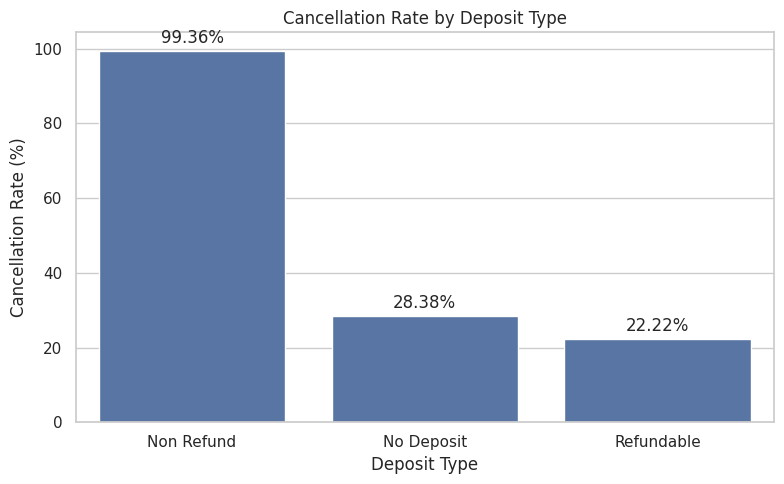

In [31]:
# Calculating cancellation rates by deposit type
deposit_cancellation = (
    df.groupby("deposit_type")["is_canceled"].mean() * 100
).sort_values(ascending=False)

# Visualising cancellation rates by deposit type
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=deposit_cancellation.index,
    y=deposit_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()



### Cancellation Rate by Customer Type
This section compares booking cancellation rates across customer types.


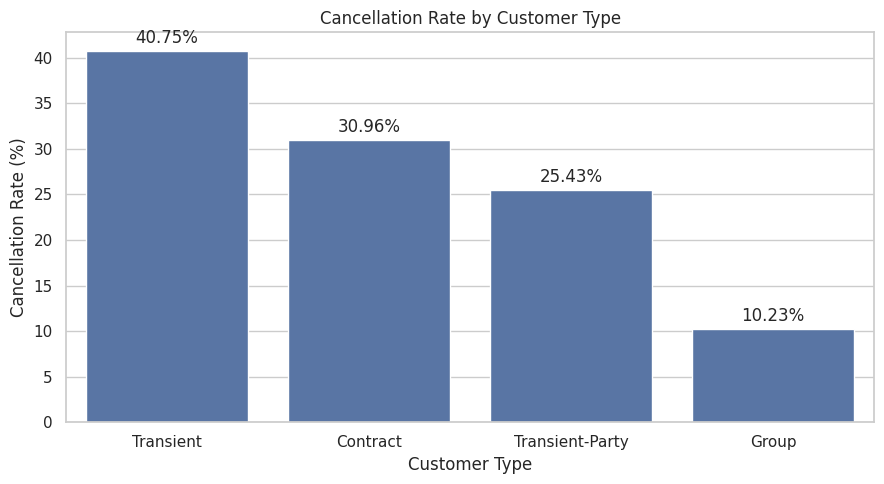

In [32]:
# Calculating cancellation rates by customer type
customer_cancellation = (
    df.groupby("customer_type")["is_canceled"].mean() * 100
).sort_values(ascending=False)

# Visualising cancellation rates by customer type
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=customer_cancellation.index,
    y=customer_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()


### Cancellation Rate by Lead Time
This section compares cancellation rates across booking lead-time groups.


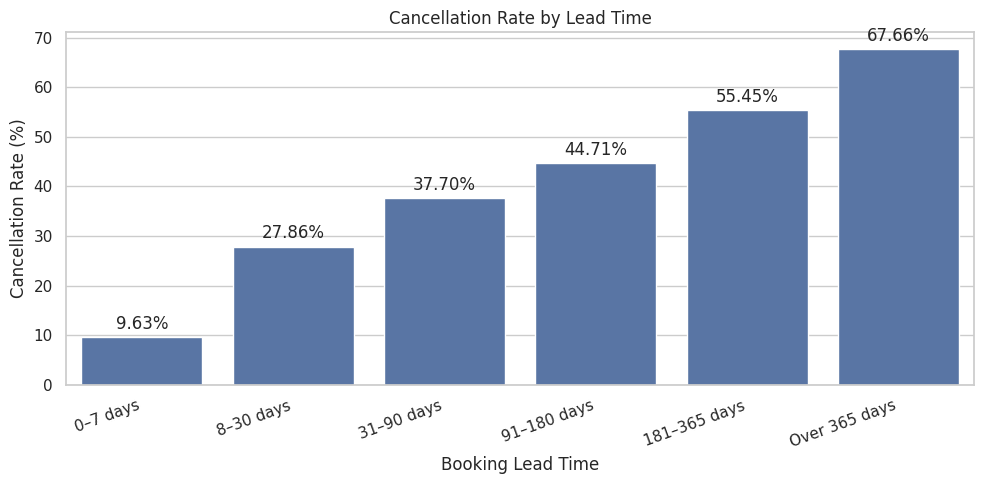

In [33]:
# Grouping bookings by lead time
df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, float("inf")],
    labels=[
        "0–7 days",
        "8–30 days",
        "31–90 days",
        "91–180 days",
        "181–365 days",
        "Over 365 days"
    ]
)

# Calculating cancellation rates for each lead-time group
lead_time_cancellation = (
    df.groupby("lead_time_group", observed=False)["is_canceled"].mean() * 100
)

# Visualising cancellation rates by lead-time group
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=lead_time_cancellation.index.astype(str),
    y=lead_time_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Booking Lead Time")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


### Cancellation Rate by Previous Cancellations
This section examines the relationship between previous cancellations and current booking cancellations.


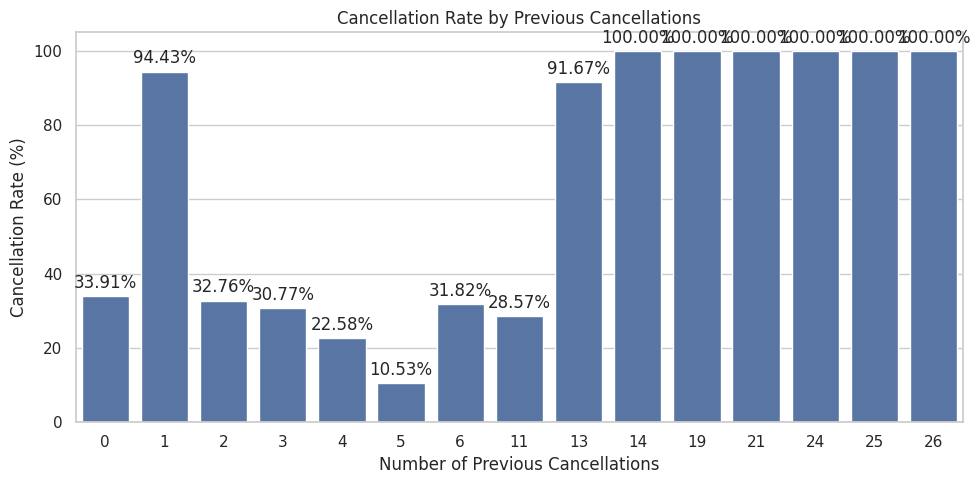

In [35]:

# Grouping bookings by previous cancellation history
previous_cancellation_rate = (
    df.groupby("previous_cancellations")["is_canceled"].mean() * 100
)

# Counting bookings in each previous cancellation group
previous_cancellation_counts = (
    df.groupby("previous_cancellations")["is_canceled"].count()
)

# Combining cancellation rates and booking counts
previous_cancellation_summary = pd.DataFrame({
    "Cancellation Rate (%)": previous_cancellation_rate,
    "Booking Count": previous_cancellation_counts
})

# Visualising cancellation rates by previous cancellations
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=previous_cancellation_rate.index,
    y=previous_cancellation_rate.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Previous Cancellations")
plt.xlabel("Number of Previous Cancellations")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()


### Previous Cancellation History Analysis
This section checks booking counts alongside cancellation rates to identify groups with limited data.


In [36]:

# Summarising booking counts and cancellation rates
previous_cancellation_summary = df.groupby("previous_cancellations")[
    "is_canceled"
].agg(
    Booking_Count="count",
    Cancelled_Bookings="sum",
    Cancellation_Rate="mean"
)

previous_cancellation_summary["Cancellation_Rate"] *= 100

# Displaying the summary for each previous cancellation count
display(previous_cancellation_summary.round(2))


,Booking_Count,Cancelled_Bookings,Cancellation_Rate
previous_cancellations,,,
0,112906,38282,33.91
1,6051,5714,94.43
2,116,38,32.76
3,65,20,30.77
4,31,7,22.58
5,19,2,10.53
6,22,7,31.82
11,35,10,28.57
13,12,11,91.67



### Cancellation Rate by Special Requests
This section compares cancellation rates according to the number of special requests made.


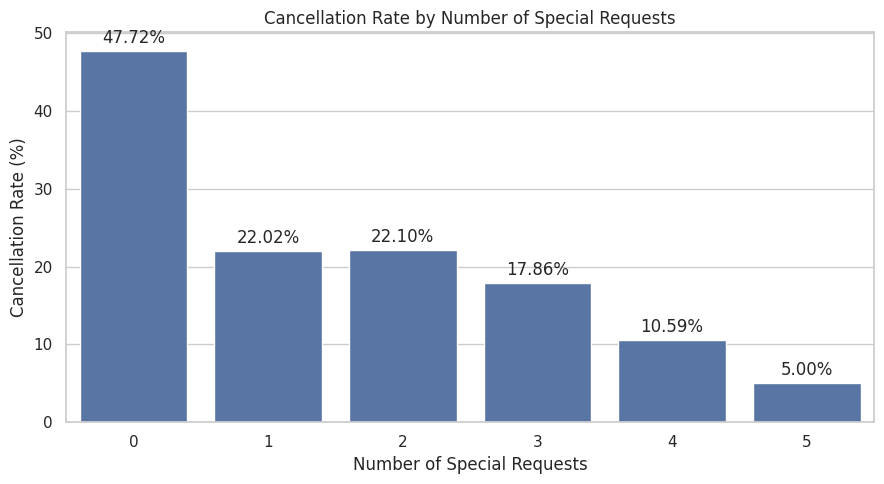

In [38]:

# Calculating cancellation rates by number of special requests
special_request_cancellation = (
    df.groupby("total_of_special_requests")["is_canceled"].mean() * 100
)

# Counting bookings in each special request category
special_request_counts = df.groupby(
    "total_of_special_requests"
)["is_canceled"].count()

# Visualising cancellation rates by special requests
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=special_request_cancellation.index,
    y=special_request_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Number of Special Requests")
plt.xlabel("Number of Special Requests")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

# Displaying cancellation rates and booking counts
special_request_summary = pd.DataFrame({
    "Booking Count": special_request_counts,
    "Cancellation Rate (%)": special_request_cancellation
})
